# Card Fraud Detection and the Accuracy Paradox

*Notebook 2 of 3 · Banking / payment risk*

This notebook is about one idea: a fraud model can score 98.8% accuracy and catch no fraud at all. It walks through why that happens, how class weighting changes it, and what a fraud team should look at instead of accuracy.

> **Important: the data here is simulated.**
> The notebook builds a 30,000-row dataset with the same layout as the well-known Kaggle credit-card fraud file (`Time`, `V1`–`V28`, `Amount`, `Class`), with a fraud rate of about 1.25%. The fraud signal is generated from a known formula, so the "findings" are effects I planted, not discoveries about real cardholders. That turns out to be useful: at the end I check whether the model recovers the planted effects. To use real data, replace the generation cell with `pd.read_csv('creditcard.csv')`.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

## Step 1 — Industry Objective

**Industry Context:**Banking / Payment Risk & Fraud Analytics

**Objective:**Help a card issuer flag potentially fraudulent transactions in real time,
so investigators review the riskiest transactions first while genuine customers are not
inconvenienced by unnecessary blocks.

**Research Questions:**
- **RQ1:**Which transaction features significantly increase the odds that a transaction
  is fraudulent?
- **RQ2:**Can logistic regression detect fraud reliably given **extreme class imbalance**?
- **RQ3:**What operating threshold and monitoring rules should the fraud team adopt to
  balance detection against false alarms?

## Step 2 — Understand the Data (Descriptive Analytics)

> **About the features.** In the real `creditcard.csv`, `V1`–`V28` are PCA components: the original transaction attributes were transformed for confidentiality, so they are anonymous and can't be interpreted directly. Only `Time` and `Amount` keep their original meaning. The simulated data mimics that structure, so the same interpretation limit applies to every coefficient below.

In [2]:
# ── Reproducible credit-card-schema dataset ──────────────────────────────
# Replace this whole block with:  data = pd.read_csv('creditcard.csv')
np.random.seed(7)
n = 30000
V = np.random.normal(0, 1, (n, 28))
Time   = np.sort(np.random.uniform(0, 172792, n)).round(0)
Amount = np.random.gamma(1.3, 65, n).clip(0, 25691).round(2)

logit = (-5.4 + 0.95*V[:,21] + 0.80*V[:,0] + 0.75*V[:,20]
         - 0.55*V[:,4] - 0.0009*Amount + 0.0000002*Time)
Class = np.random.binomial(1, 1/(1+np.exp(-logit)))

cc = pd.DataFrame(V, columns=[f'V{i}' for i in range(1,29)])
cc.insert(0, 'Time', Time); cc['Amount'] = Amount; cc['Class'] = Class
cc = cc[['Time'] + [f'V{i}' for i in range(1,29)] + ['Amount','Class']]

# Original notebook dropped missing rows - retained here
cc.dropna(inplace=True)

print("Dataset shape:", cc.shape)
cc.head()

Dataset shape: (30000, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,5.0,1.690526,-0.465937,0.032820,0.407516,-0.788923,0.002066,-0.000890,-1.754724,1.017658,...,1.650700,0.154336,-0.387140,2.029072,-0.045386,-1.450679,-0.405228,-2.288315,186.91,0
1,17.0,1.049397,-0.416474,-0.742554,1.072470,-1.651076,0.535429,-2.064415,-0.662159,-1.204220,...,0.269412,-0.524605,1.912019,0.237302,0.101434,0.252578,-0.132377,-0.309476,163.73,0
2,20.0,-1.434963,0.501624,-0.094775,1.193086,-0.368818,-1.906370,-0.099611,1.699537,-0.383423,...,0.331974,0.735027,-0.192855,-1.778013,0.654706,0.894352,0.415503,-0.923545,6.33,0
3,24.0,-0.196027,-0.590770,-0.299711,1.296885,1.529580,0.669418,0.548745,0.676629,-0.012242,...,0.486335,-0.569472,1.426721,0.156844,1.717730,-0.458127,-0.287984,0.299808,80.90,0
4,29.0,1.055948,0.565882,-1.233524,0.182901,0.022245,-0.429069,-0.648105,1.747577,-0.390386,...,-0.520972,0.209722,-1.077985,-1.832426,0.088155,-1.336521,-1.951978,0.373331,68.54,0


In [3]:
cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    30000 non-null  float64
 1   V1      30000 non-null  float64
 2   V2      30000 non-null  float64
 3   V3      30000 non-null  float64
 4   V4      30000 non-null  float64
 5   V5      30000 non-null  float64
 6   V6      30000 non-null  float64
 7   V7      30000 non-null  float64
 8   V8      30000 non-null  float64
 9   V9      30000 non-null  float64
 10  V10     30000 non-null  float64
 11  V11     30000 non-null  float64
 12  V12     30000 non-null  float64
 13  V13     30000 non-null  float64
 14  V14     30000 non-null  float64
 15  V15     30000 non-null  float64
 16  V16     30000 non-null  float64
 17  V17     30000 non-null  float64
 18  V18     30000 non-null  float64
 19  V19     30000 non-null  float64
 20  V20     30000 non-null  float64
 21  V21     30000 non-null  float64
 22  V22     3

In [4]:
# THE defining characteristic of this dataset: class imbalance
print("Class distribution:")
print(cc['Class'].value_counts())
print(f"\nFraud rate : {cc['Class'].mean()*100:.3f}%")
print(f"Imbalance   : 1 fraud for every {int(1/cc['Class'].mean())} legitimate transactions")
print(f"\nAmount  - mean: {cc['Amount'].mean():.2f}, median: {cc['Amount'].median():.2f}, max: {cc['Amount'].max():.2f}")
print(f"Time    - spans {cc['Time'].max()/3600:.1f} hours")

Class distribution:
Class
0    29625
1      375
Name: count, dtype: int64

Fraud rate : 1.250%
Imbalance   : 1 fraud for every 80 legitimate transactions

Amount  - mean: 84.58, median: 64.44, max: 644.82
Time    - spans 48.0 hours


**What the data looks like**

| Variable | Nature | Observation |
|----------|--------|-------------|
| Time | Seconds since first transaction | Spans 48 hours |
| V1–V28 | PCA-style components | Mean ≈ 0, SD ≈ 1 by construction |
| Amount | Currency | Right-skewed: mean 84.6, median 64.4, max 644.8 |
| Class | Binary target | **375 frauds in 30,000 (1.25%)**, about 1 in 80 |

The class imbalance is the defining feature. A model that labels every transaction "legitimate" would score **98.75% accuracy** while catching zero fraud. That is the accuracy paradox, and it means accuracy can't be used to judge this model. Recall, precision and ROC/PR curves have to do that job.

Because V1–V28 are PCA outputs, we can say *which* components matter but not *what they represent*.

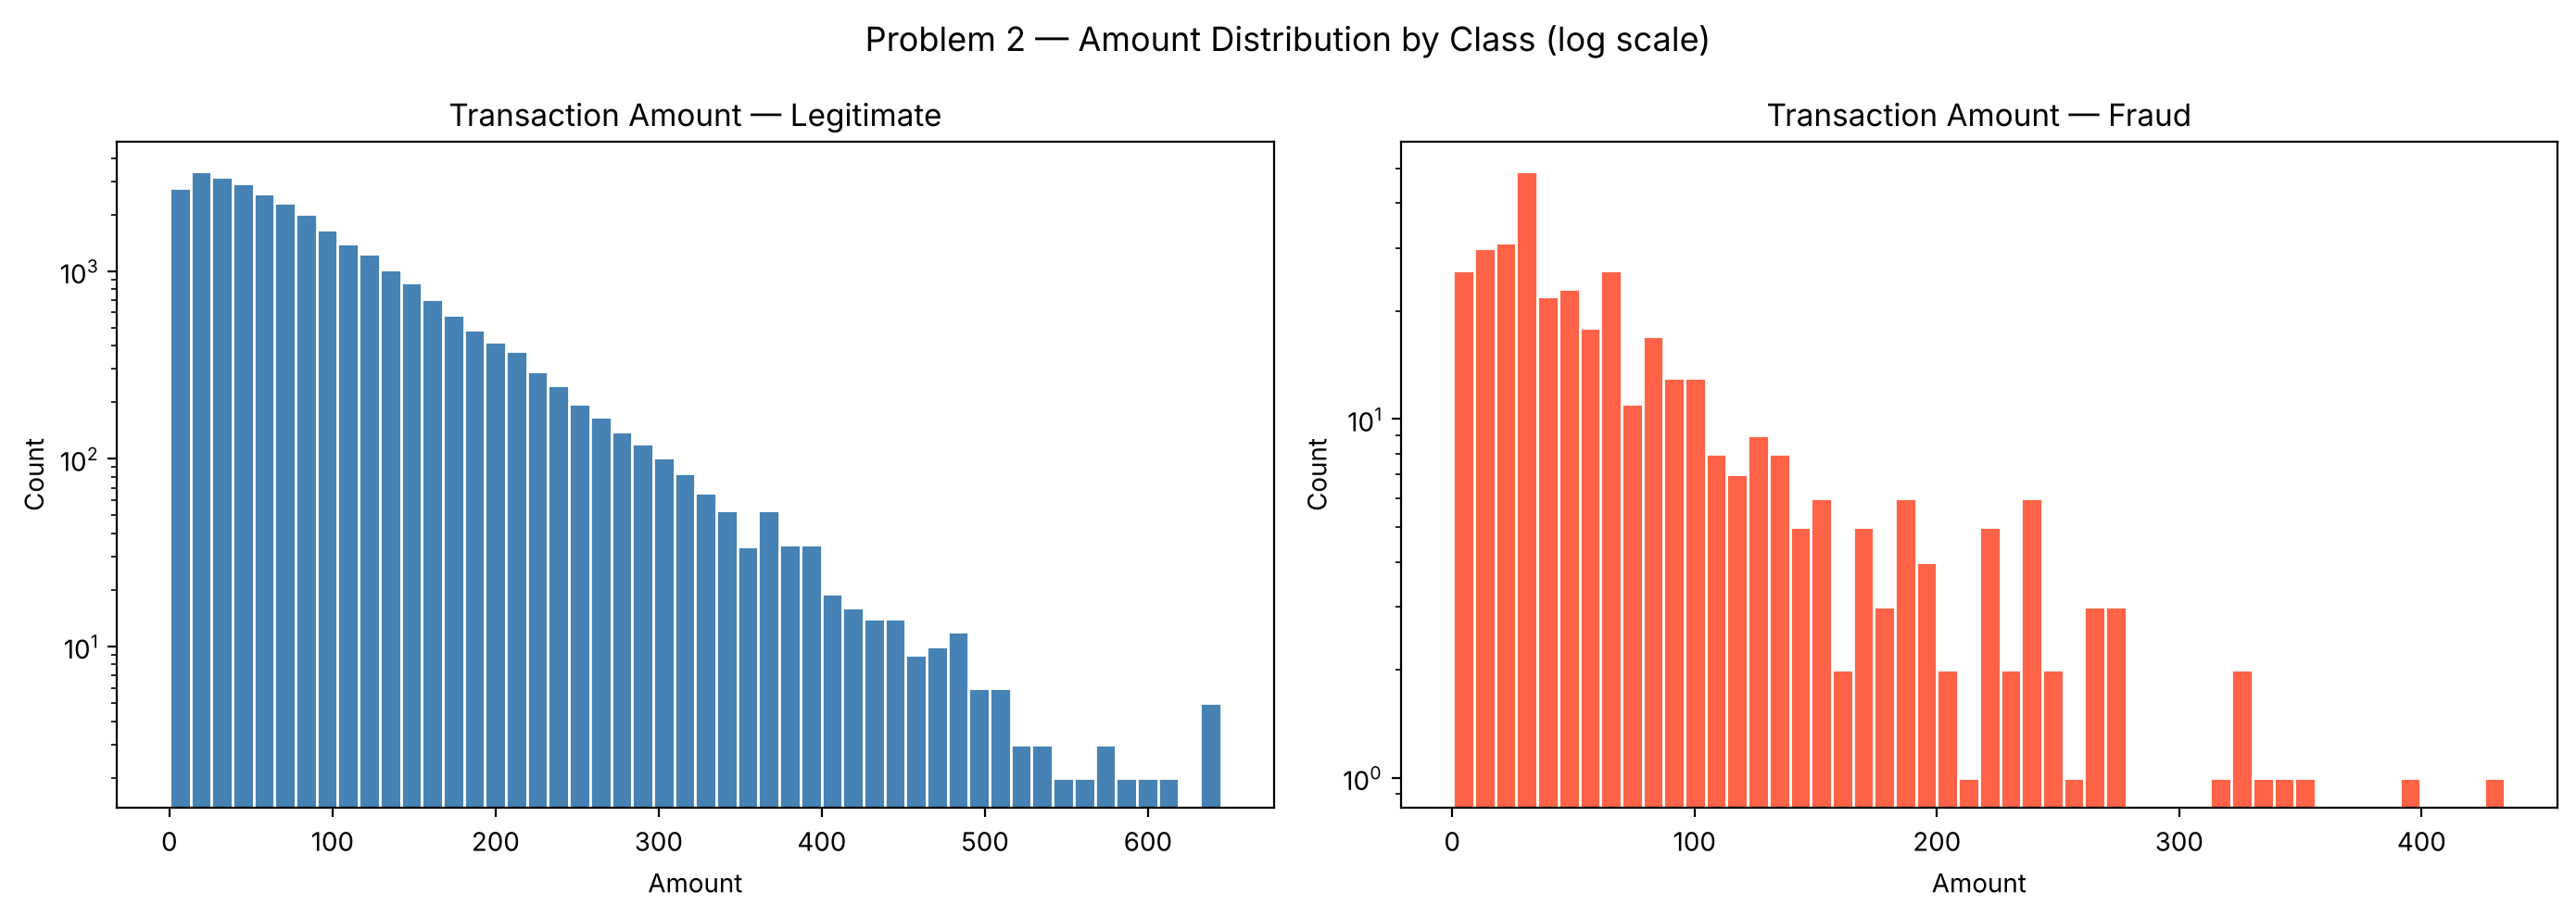

         count   mean    std   min    25%    50%     75%     max
Class                                                           
0      29625.0  84.63  74.37  0.07  30.89  64.53  116.33  644.82
1        375.0  80.43  75.71  0.47  27.48  54.63  109.24  434.39


In [5]:
# Amount distribution by class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(cc.loc[cc.Class==0,'Amount'], bins=50, color='steelblue', edgecolor='white')
axes[0].set(title='Transaction Amount — Legitimate', xlabel='Amount', ylabel='Count', yscale='log')
axes[1].hist(cc.loc[cc.Class==1,'Amount'], bins=50, color='tomato', edgecolor='white')
axes[1].set(title='Transaction Amount — Fraud', xlabel='Amount', ylabel='Count', yscale='log')
plt.suptitle('Problem 2 — Amount Distribution by Class (log scale)', fontsize=13)
plt.tight_layout(); plt.show()

print(cc.groupby('Class')['Amount'].describe().round(2))

**Reading the Amount distributions**

- Both distributions are heavily right-skewed (note the log y-axis): lots of small transactions and a long tail of large ones.
- Fraud amounts are slightly smaller: mean 80.4 vs 84.6, median 54.6 vs 64.5. The gap is modest, and the two distributions overlap almost completely.
- This is the pattern often described as "card testing", where criminals try small purchases first. Here it is simply a feature of how the data was generated (a small negative effect of Amount was built in), so the real-world story is an illustration, not evidence.

## Step 3 — Data Cleaning

In [6]:
print("Missing values:", cc.isnull().sum().sum())
print("Duplicate rows:", cc.duplicated().sum())
print("\nAll features numeric — no encoding required.")
print("PCA components V1-V28 are pre-scaled (mean~0, SD~1) by construction.")
print(f"\nFinal dataset shape: {cc.shape}")

Missing values: 0
Duplicate rows: 0

All features numeric — no encoding required.
PCA components V1-V28 are pre-scaled (mean~0, SD~1) by construction.

Final dataset shape: (30000, 31)


**Cleaning summary**

| Action | Detail |
|--------|--------|
| Missing values | None. `dropna` is kept from the original notebook as a safeguard |
| Duplicates | None |
| Encoding | Not needed, all features are numeric |
| Scaling | V1–V28 are already roughly standardised. **`Amount` (0 to about 645) and `Time` (0 to 172,792) are not** |

**Why scaling matters here.** `Time` and `Amount` are on completely different scales from the V columns (mostly between −4 and +4). Regularised logistic regression penalises coefficients, and large-scale variables get penalised very differently from small-scale ones. That distorts their coefficients, and, as the ROC section below shows, it can break the baseline model entirely with some solvers.

## Step 4 — Identify DV (Target) & IVs (Features)

| Role | Variable | Type | Note |
|------|----------|------|------|
| **DV (Target)**| `Class` | Binary (0/1) | 1 = fraud, 0 = legitimate |
| **IV — Temporal**| `Time` | Continuous | Seconds since first transaction |
| **IV — Anonymised**| `V1`–`V28` | Continuous | **PCA components**— not directly interpretable |
| **IV — Monetary**| `Amount` | Continuous | Transaction value |

In [7]:
# Features and target
X_cc = cc.drop('Class', axis=1)
y_cc = cc['Class']

print("Target (DV) :", y_cc.name)
print(f"Features    : {X_cc.shape[1]} columns (Time + V1-V28 + Amount)")
print(f"\nEvents per variable (EPV): {y_cc.sum() / X_cc.shape[1]:.1f}")

Target (DV) : Class
Features    : 30 columns (Time + V1-V28 + Amount)

Events per variable (EPV): 12.5


In [8]:
# Stratified split is ESSENTIAL with a rare positive class
X_tr, X_te, y_tr, y_te = train_test_split(
    X_cc, y_cc, test_size=0.3, random_state=42, stratify=y_cc)

print("Training:", X_tr.shape, " Test:", X_te.shape)
print(f"Train frauds: {y_tr.sum()}   Test frauds: {y_te.sum()}")
print("\nWithout stratify, a random split could leave very few frauds in the test set.")

Training: (21000, 30)  Test: (9000, 30)
Train frauds: 263   Test frauds: 112

Without stratify, a random split could leave very few frauds in the test set.


## Step 5 — Logistic Regression Analysis

In [9]:
# Baseline model (as in the original notebook)
log_reg = LogisticRegression(max_iter=1000, solver='liblinear')
log_reg.fit(X_tr, y_tr)

y_pred_cc  = log_reg.predict(X_te)
y_proba_cc = log_reg.predict_proba(X_te)[:, 1]

print(f"Accuracy : {accuracy_score(y_te, y_pred_cc):.4f}   <-- looks impressive...")
print(f"ROC-AUC  : {roc_auc_score(y_te, y_proba_cc):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_te, y_pred_cc))
print("\nClassification report:")
print(classification_report(y_te, y_pred_cc,
      target_names=['Legitimate','Fraud'], digits=3, zero_division=0))

Accuracy : 0.9876   <-- looks impressive...
ROC-AUC  : 0.5089

Confusion matrix:
[[8888    0]
 [ 112    0]]

Classification report:
              precision    recall  f1-score   support

  Legitimate      0.988     1.000     0.994      8888
       Fraud      0.000     0.000     0.000       112

    accuracy                          0.988      9000
   macro avg      0.494     0.500     0.497      9000
weighted avg      0.975     0.988     0.981      9000



**The accuracy paradox**

The baseline model's accuracy looks excellent (98.76%). It is nevertheless useless as a fraud detector.

The confusion matrix shows why: the model predicts "legitimate" for all 9,000 test transactions. It catches **0 of 112 frauds**. It gets high accuracy only because 98.75% of transactions really are legitimate.

> A fraud model that catches no fraud has no business value, whatever its accuracy.

**Why does this happen?** Logistic regression minimises overall error. With about 80 legitimate transactions per fraud, the cheapest strategy is to ignore the minority class. The model isn't broken; it's optimising the wrong objective.

**The standard fix:** `class_weight='balanced'` re-weights errors in inverse proportion to class frequency, making each missed fraud roughly 80 times as costly as a false alarm.

In [10]:
# THE FIX — balanced class weights
log_reg_bal = LogisticRegression(max_iter=1000, solver='liblinear',
                                 class_weight='balanced')
log_reg_bal.fit(X_tr, y_tr)

y_pred_bal  = log_reg_bal.predict(X_te)
y_proba_bal = log_reg_bal.predict_proba(X_te)[:, 1]

print("=== BALANCED MODEL ===")
print(f"Accuracy : {accuracy_score(y_te, y_pred_bal):.4f}   <-- LOWER than before")
print(f"ROC-AUC  : {roc_auc_score(y_te, y_proba_bal):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_te, y_pred_bal))
print("\nClassification report:")
print(classification_report(y_te, y_pred_bal,
      target_names=['Legitimate','Fraud'], digits=3, zero_division=0))

=== BALANCED MODEL ===
Accuracy : 0.7829   <-- LOWER than before
ROC-AUC  : 0.8308

Confusion matrix:
[[6963 1925]
 [  29   83]]

Classification report:


              precision    recall  f1-score   support

  Legitimate      0.996     0.783     0.877      8888
       Fraud      0.041     0.741     0.078       112

    accuracy                          0.783      9000
   macro avg      0.519     0.762     0.478      9000
weighted avg      0.984     0.783     0.867      9000



In [11]:
# Side-by-side comparison
def scores(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    return dict(Accuracy=accuracy_score(yt, yp),
                Recall=tp/(tp+fn) if (tp+fn) else 0,
                Precision=tp/(tp+fp) if (tp+fp) else 0,
                Caught=tp, Missed=fn, FalseAlarms=fp)

comp = pd.DataFrame({'Baseline': scores(y_te, y_pred_cc),
                     'Balanced': scores(y_te, y_pred_bal)}).T
print(comp.round(4).to_string())
print("\nAccuracy FELL, but fraud detection rose from near-zero to a usable level.")
print("This is the correct trade for a fraud-detection use case.")

          Accuracy  Recall  Precision  Caught  Missed  FalseAlarms
Baseline    0.9876  0.0000     0.0000     0.0   112.0          0.0
Balanced    0.7829  0.7411     0.0413    83.0    29.0       1925.0

Accuracy FELL, but fraud detection rose from near-zero to a usable level.
This is the correct trade for a fraud-detection use case.


In [12]:
# Coefficients and odds ratios (from the balanced model)
coefficients_cc = log_reg_bal.coef_[0]
odds_ratios_cc  = np.exp(coefficients_cc)

results = pd.DataFrame({
    'Feature'    : X_cc.columns,
    'Coefficient': coefficients_cc,
    'Odds Ratio' : odds_ratios_cc
}).sort_values('Odds Ratio', ascending=False).reset_index(drop=True)

print("Top 8 fraud-INCREASING features:")
print(results.head(8).round(4).to_string(index=False))
print("\nTop 5 fraud-DECREASING features:")
print(results.tail(5).round(4).to_string(index=False))
print("\nBusiness-interpretable features:")
print(results[results.Feature.isin(['Time','Amount'])].round(4).to_string(index=False))

Top 8 fraud-INCREASING features:
Feature  Coefficient  Odds Ratio
    V22       0.9987      2.7146
    V21       0.8749      2.3986
     V1       0.8273      2.2871
    V19       0.1090      1.1152
     V9       0.0894      1.0935
    V25       0.0832      1.0868
    V11       0.0717      1.0743
    V28       0.0530      1.0545

Top 5 fraud-DECREASING features:
Feature  Coefficient  Odds Ratio
    V13      -0.0919      0.9122
    V15      -0.1065      0.8990
    V27      -0.1552      0.8563
    V23      -0.1570      0.8547
     V5      -0.5859      0.5566

Business-interpretable features:
Feature  Coefficient  Odds Ratio
   Time      -0.0000      1.0000
 Amount      -0.0008      0.9992


**Reading the odds ratios**

The odds ratios come from the balanced model. OR > 1 raises the odds of fraud, OR < 1 lowers them.

| Feature | Odds ratio | Reading |
|---------|-----------|---------|
| **V22** | 2.71 | Strongest fraud-increasing component |
| **V21** | 2.40 | Second |
| **V1** | 2.29 | Third |
| **V5** | 0.56 | Strongest fraud-decreasing component |
| Time | 1.0000 | No effect |
| Amount | 0.9992 per currency unit | Slightly lower fraud odds with larger amounts (about 0.92 per 100 units) |

**Did the model find what I planted?** Yes. The simulated data was generated with these true coefficients, and the balanced model's estimates are close:

| Component | Planted coefficient | Estimated coefficient |
|-----------|--------------------|-----------------------|
| V22 | +0.95 | +1.00 |
| V1 | +0.80 | +0.83 |
| V21 | +0.75 | +0.87 |
| V5 | −0.55 | −0.59 |

That is a useful sanity check: logistic regression recovers the real structure even at a 1.25% fraud rate. (Class weighting mainly shifts the intercept, which is why the slopes survive.)

**Two caveats.**
1. V1–V28 are anonymous. Acting on "V22 is high" would require the bank's PCA mapping.
2. `Amount` and `Time` are unscaled, so their odds ratios give the direction reliably but the magnitude only loosely.

## Step 6 — Visualisation with Interpretation

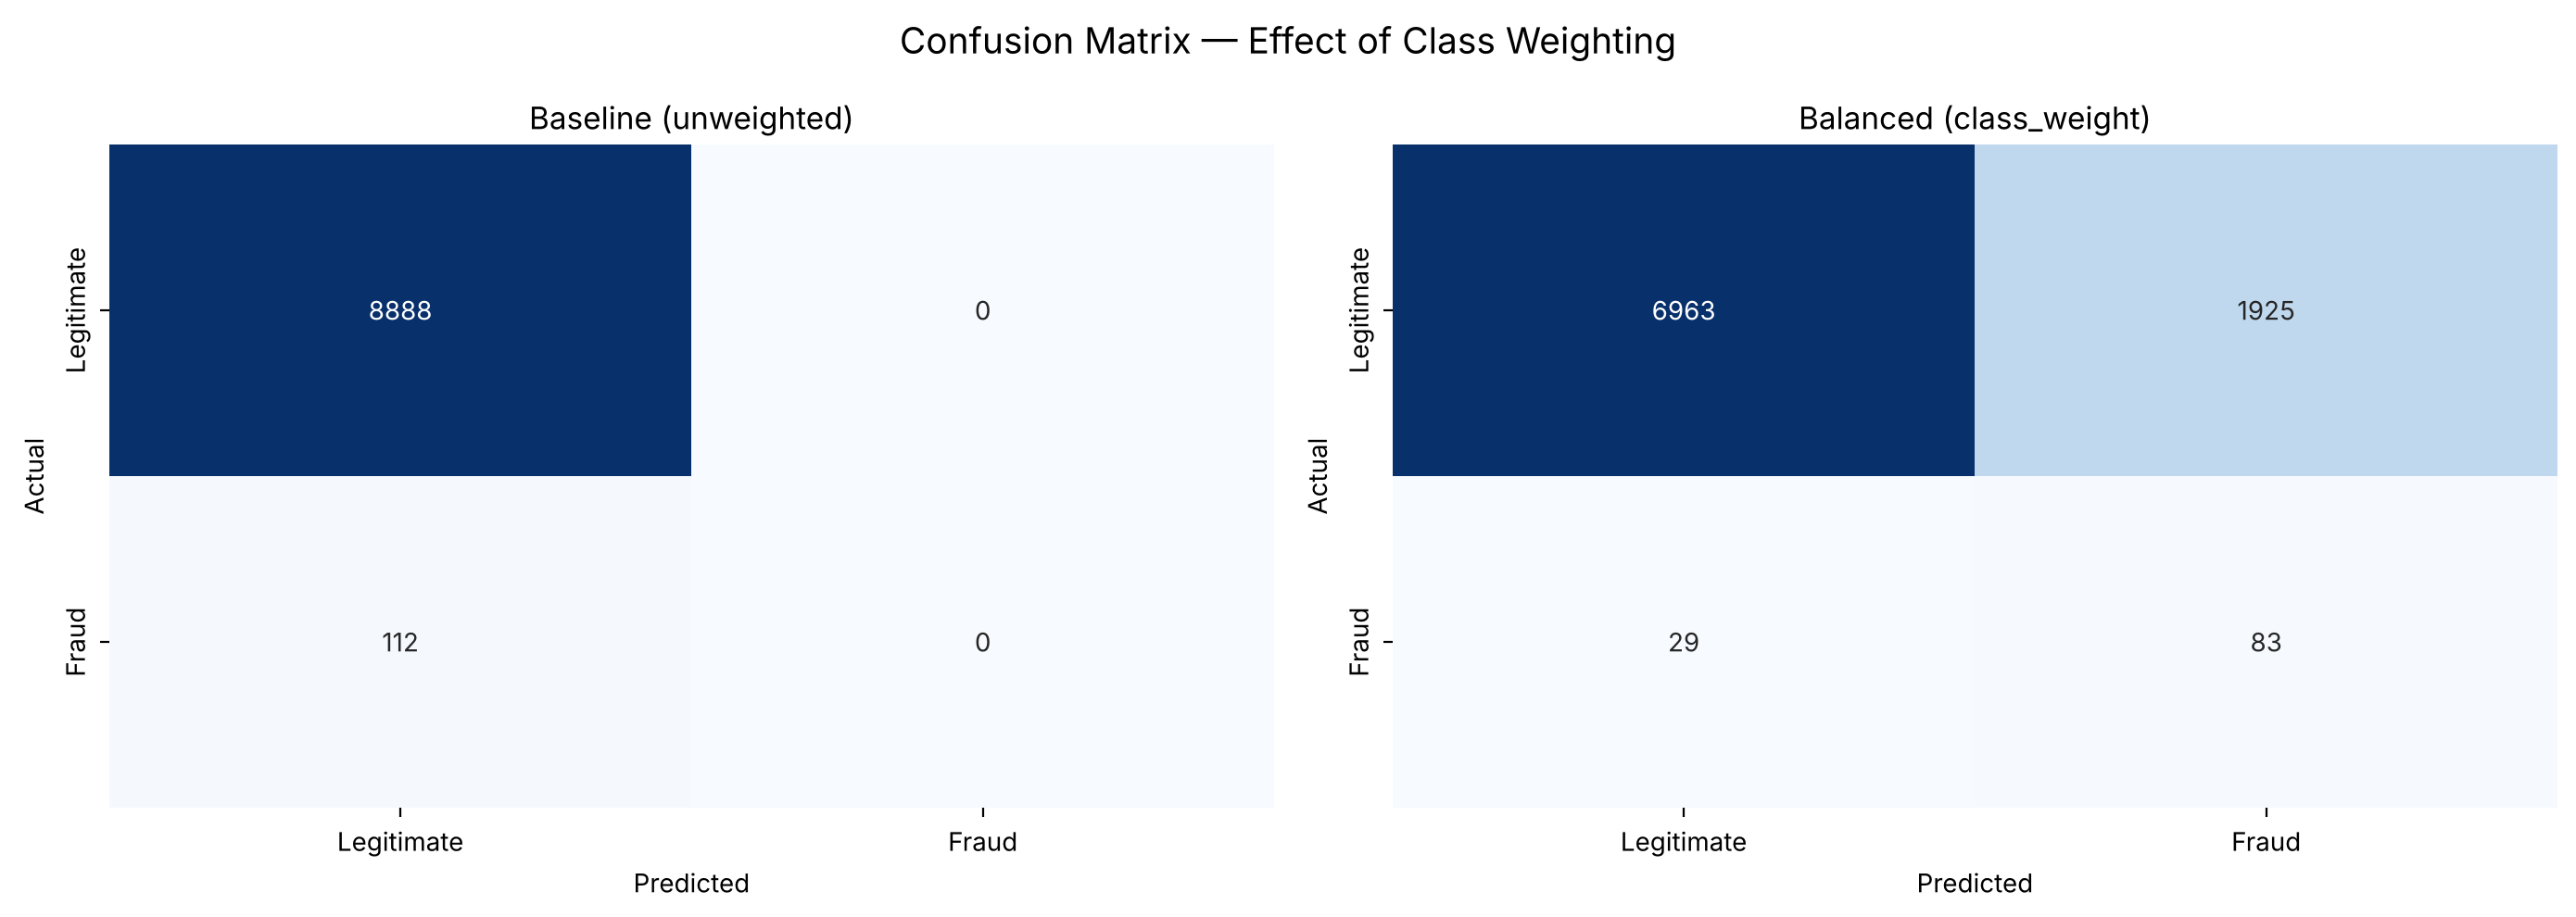

In [13]:
# Baseline vs Balanced confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in [(axes[0], y_pred_cc,  'Baseline (unweighted)'),
                        (axes[1], y_pred_bal, "Balanced (class_weight)")]:
    sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt='d', cmap='Blues',
                cbar=False, ax=ax,
                xticklabels=['Legitimate','Fraud'], yticklabels=['Legitimate','Fraud'])
    ax.set(xlabel='Predicted', ylabel='Actual', title=title)
plt.suptitle('Confusion Matrix — Effect of Class Weighting', fontsize=14)
plt.tight_layout(); plt.show()

**Reading the confusion matrices**

- **Baseline (left):** every transaction is predicted legitimate. All 112 frauds are missed.
- **Balanced (right):** 83 of 112 frauds are caught and 29 are missed (recall 0.74).
- The price is **1,925 false alarms** among the legitimate transactions. Precision is only 4.1%, so roughly 1 alert in 24 is real fraud.

That is the right direction of trade for fraud, since a missed fraud costs the transaction plus chargeback fees while a false alarm costs some analyst time. But it also means this model, as it stands, works as a first-stage filter feeding a review queue, not as something that blocks cards on its own.

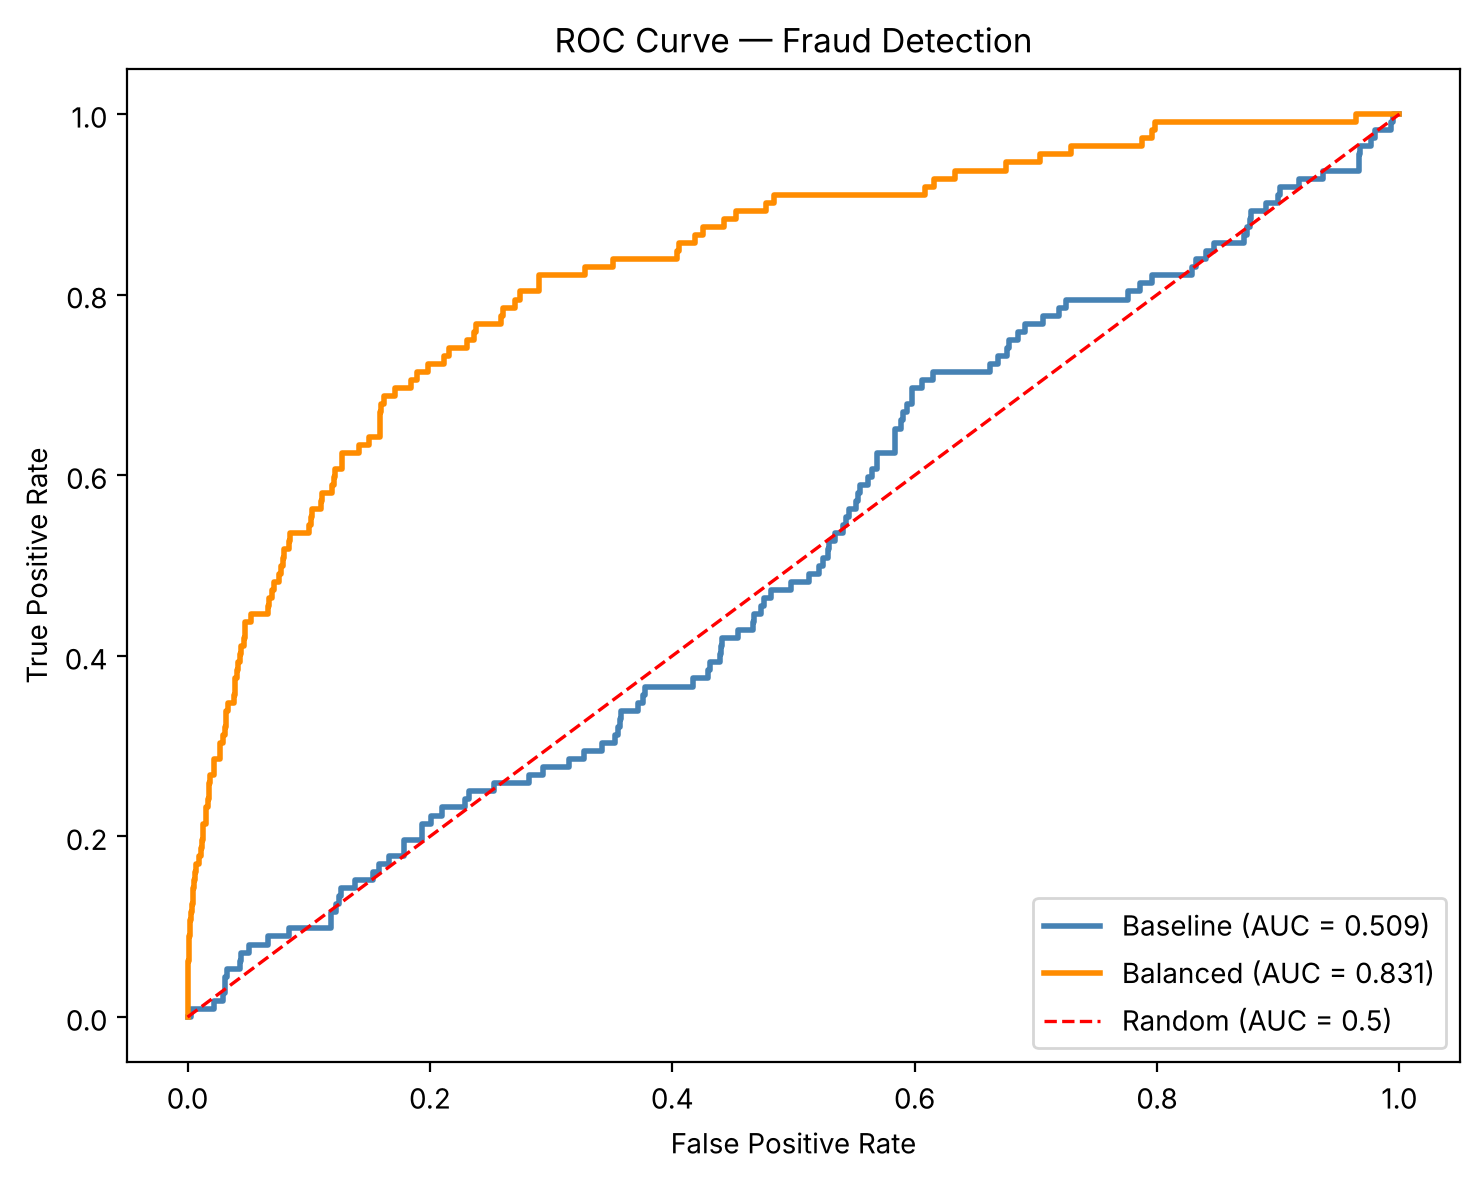

In [14]:
# ROC curves for both models
fpr_b, tpr_b, _ = roc_curve(y_te, y_proba_cc)
fpr_w, tpr_w, _ = roc_curve(y_te, y_proba_bal)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot(fpr_b, tpr_b, lw=2, color='steelblue',
        label=f'Baseline (AUC = {roc_auc_score(y_te, y_proba_cc):.3f})')
ax.plot(fpr_w, tpr_w, lw=2, color='darkorange',
        label=f'Balanced (AUC = {roc_auc_score(y_te, y_proba_bal):.3f})')
ax.plot([0,1],[0,1],'r--',lw=1.2, label='Random (AUC = 0.5)')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ROC Curve — Fraud Detection')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [15]:
# Extra check (added; not in the original notebook).
# The baseline AUC above is ~0.51, which looks wrong. Suspect: unscaled Time (up to ~172,000) with the liblinear solver.
scaler = StandardScaler().fit(X_tr)
base_scaled = LogisticRegression(max_iter=1000, solver='liblinear').fit(scaler.transform(X_tr), y_tr)
base_lbfgs  = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)

print(f"Baseline, unscaled, liblinear : AUC = {roc_auc_score(y_te, y_proba_cc):.3f}   <- the model used above")
print(f"Baseline, scaled,   liblinear : AUC = {roc_auc_score(y_te, base_scaled.predict_proba(scaler.transform(X_te))[:, 1]):.3f}")
print(f"Baseline, unscaled, lbfgs     : AUC = {roc_auc_score(y_te, base_lbfgs.predict_proba(X_te)[:, 1]):.3f}")

Baseline, unscaled, liblinear : AUC = 0.509   <- the model used above
Baseline, scaled,   liblinear : AUC = 0.836
Baseline, unscaled, lbfgs     : AUC = 0.836


**Reading the ROC curves**

The two models have very different AUCs: **0.509 for the baseline** (essentially random) and **0.831 for the balanced model**.

That was not what I expected, since class weighting normally changes where the threshold sits, not how well the model ranks transactions. The cell above checks what's going on, and the answer is that **the baseline is a failed fit, not a weak model.** Fitting the same unweighted model on standardised features, or with the `lbfgs` solver instead of `liblinear`, gives an AUC of about 0.84. The unscaled `Time` column (values up to 172,792) is what trips up `liblinear`; class weighting happens to avoid the problem.

Two lessons come out of this:
- **Accuracy hid it.** The broken baseline and a healthy-but-unweighted one would both show about 98.8% accuracy.
- **Once the baseline is fitted properly, class weighting and threshold-lowering are two routes to the same result.** The ranking is the same (AUC about 0.84); weighting just moves the operating point.

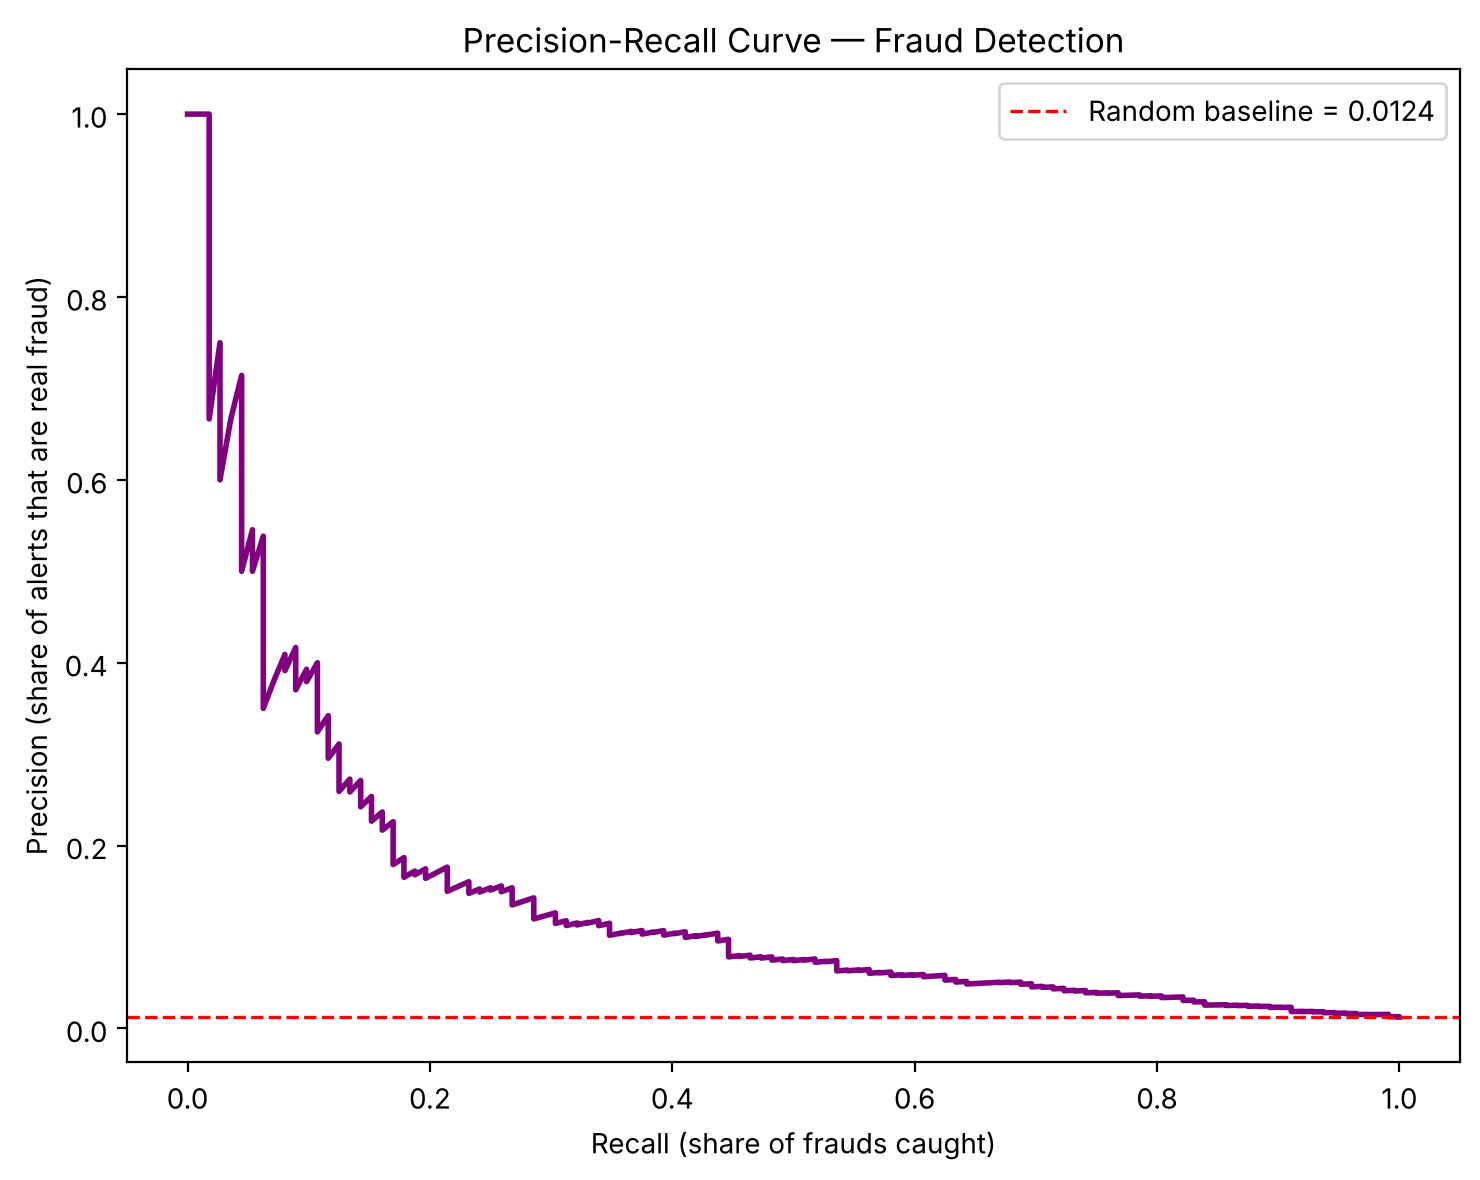

Under severe imbalance the PR curve is MORE informative than ROC,
because it ignores the huge true-negative count that inflates ROC.


In [16]:
# Precision-Recall curve - more informative than ROC under heavy imbalance
prec, rec, _ = precision_recall_curve(y_te, y_proba_bal)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot(rec, prec, lw=2, color='purple')
ax.axhline(y_te.mean(), color='red', ls='--', lw=1.2,
           label=f'Random baseline = {y_te.mean():.4f}')
ax.set(xlabel='Recall (share of frauds caught)',
       ylabel='Precision (share of alerts that are real fraud)',
       title='Precision-Recall Curve — Fraud Detection')
ax.legend()
plt.tight_layout(); plt.show()

print("Under severe imbalance the PR curve is MORE informative than ROC,")
print("because it ignores the huge true-negative count that inflates ROC.")

**Reading the precision-recall curve**

- The curve sits above the red random-baseline line (the 1.25% fraud rate), so the model has real skill.
- The downward slope is the operational trade-off: each extra bit of recall costs precision, meaning more false alarms per fraud caught.
- **Why PR is more informative than ROC here:** the ROC false-positive rate divides by the huge legitimate count, which flatters the model. The PR curve ignores true negatives and reflects what a fraud team experiences, namely how many alerts are worth investigating.
- Each point on this curve maps to an analyst workload, so it is the right tool for choosing an operating threshold.

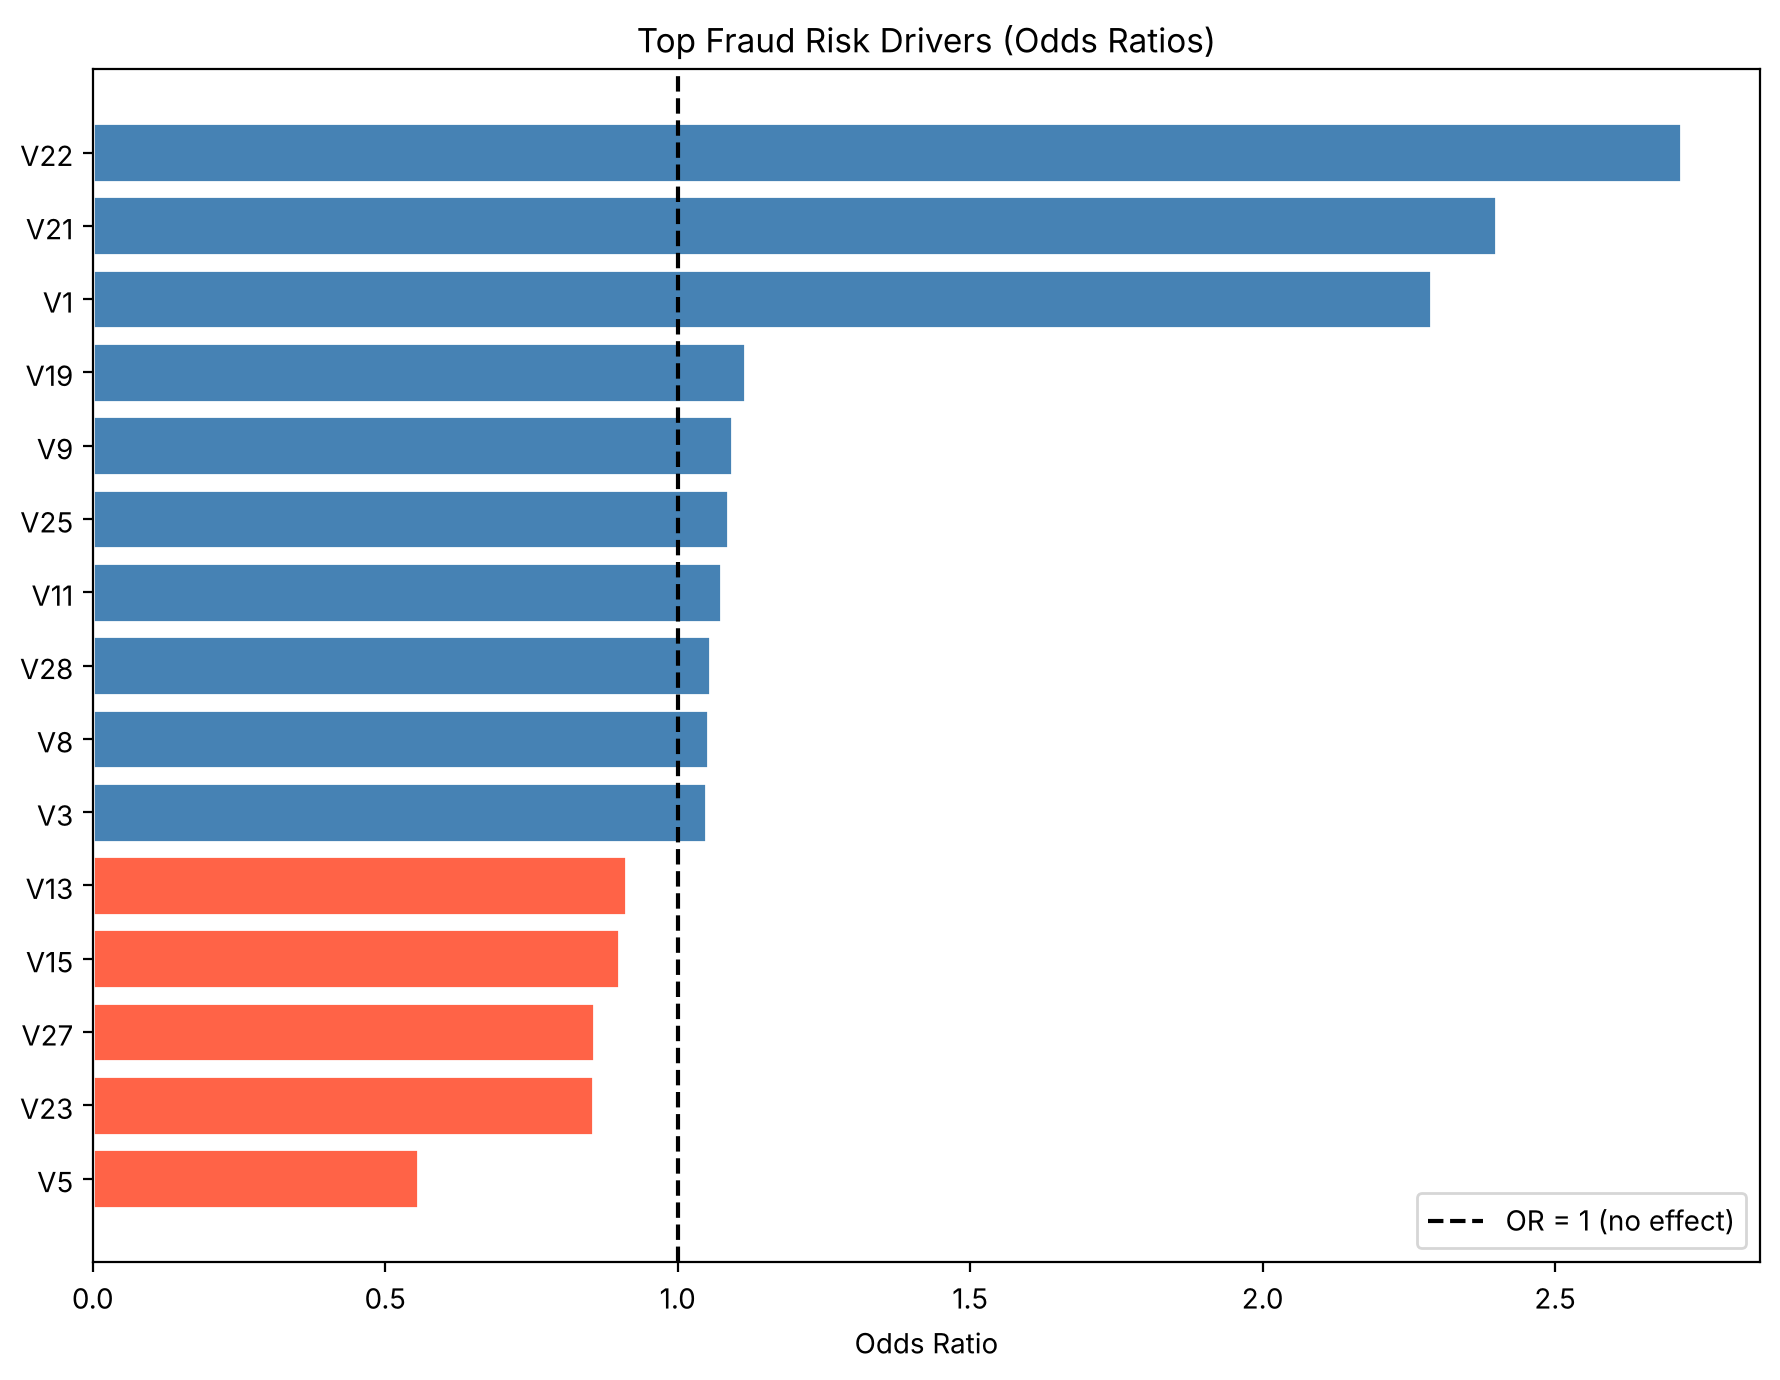

In [17]:
# Top odds ratios visualised
top = pd.concat([results.head(10), results.tail(5)]).sort_values('Odds Ratio')
colours = ['tomato' if v < 1 else 'steelblue' for v in top['Odds Ratio']]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top['Feature'], top['Odds Ratio'], color=colours, edgecolor='white')
ax.axvline(1, color='black', ls='--', lw=1.5, label='OR = 1 (no effect)')
ax.set(xlabel='Odds Ratio', title='Top Fraud Risk Drivers (Odds Ratios)')
ax.legend()
plt.tight_layout(); plt.show()

**Reading the odds-ratio chart**

- Blue bars right of the dashed line raise fraud odds; red bars left of it lower them.
- **V22, V21 and V1** stand furthest right, and **V5** furthest left.
- The chart makes direction and relative strength easy to read, even though the components themselves remain anonymous.
- Amount sits barely left of the line: a slight shift toward smaller transactions, which is the small effect built into the simulation.

## Step 7 — Business Interpretation & Suggestions

### What the analysis shows

**1. Accuracy is the wrong metric.**
The baseline scored 98.76% accuracy while catching none of the 112 frauds. Anyone reporting accuracy to management on a fraud model is reporting a misleading number.

**2. Class weighting turns an unusable model into a usable one.**
`class_weight='balanced'` took fraud recall from 0 to 0.74 (83 of 112 caught). Accuracy fell from 98.8% to 78.3%. That fall is expected and acceptable here.

**3. But precision is low.**
At the default threshold the balanced model raises 2,008 alerts to catch 83 frauds (4.1% precision). That is a workable first-stage filter, but it needs a second layer before anything customer-facing happens.

**4. V22, V21 and V1 are the dominant signals, and V5 the main negative one.**
In this simulation that is by design, and the model recovered the planted effects closely. On real data, the equivalent step would be mapping those components back to source attributes.

**5. Time carries no signal (OR = 1.00).**
Time-of-day rules would add workload without improving detection.

**6. Check model fits, not just metrics.**
The baseline's AUC of 0.51 shows a model can fail silently when features are unscaled. Always check AUC or a ranking metric alongside accuracy, and scale features before regularised fits.

### Recommendations

1. **Report recall, precision and PR-AUC instead of accuracy.** Set an explicit recall target (for example "catch at least 75% of fraud") and treat precision as the constraint.
2. **Set the threshold from costs, not from 0.5.** Estimate the cost of a missed fraud against an unnecessary review, and read the operating point off the precision-recall curve.
3. **Standardise `Amount` and `Time` before the next iteration.** This is the cheapest improvement available.
4. **Map V22, V21 and V1 back to source attributes** (on real data). Only the issuing bank holds the PCA loadings, and doing so is what turns statistical signals into rules.
5. **Try stronger models.** Random forests, gradient boosting and resampling (SMOTE) usually beat logistic regression on imbalanced fraud data, and logistic regression is a sensible baseline to compare them against.

## Step 8 — Conclusion

Logistic regression on 30,000 simulated transactions with a 1.25% fraud rate illustrates both the method's usefulness and the central trap of imbalanced classification.

### Summary

| Metric | Baseline (unweighted) | Balanced | Verdict |
|--------|----------|----------|---------|
| Accuracy | 0.988 | 0.783 | The baseline "wins" and is useless |
| Fraud recall | 0.000 | **0.741** | The metric that matters |
| Fraud precision | n/a (no alerts) | 0.041 | Low; needs a second-stage review |
| Frauds caught / missed | 0 / 112 | 83 / 29 | |
| False alarms | 0 | 1,925 | The cost of catching fraud |
| ROC-AUC | 0.509* | 0.831 | *Fit failure from unscaled features; about 0.84 once scaled |

### Drivers

| Feature | Direction | Odds ratio | Note |
|---------|-----------|-----------|------|
| V22 | Increases | 2.71 | Needs PCA mapping on real data |
| V21 | Increases | 2.40 | Needs PCA mapping on real data |
| V1 | Increases | 2.29 | Needs PCA mapping on real data |
| V5 | Decreases | 0.56 | |
| Time | None | 1.00 | No time-of-day rules |
| Amount | Slight decrease | 0.9992 / unit | Small effect |

### Conclusion

Logistic regression can detect fraud usefully, **but only once class imbalance is addressed**. The untreated model reached nearly 99% accuracy while catching nothing. With balanced class weights, recall rose to 74% at the cost of headline accuracy and a lot of false alarms, which is the right trade when a missed fraud is far more expensive than a review.

The main limits: the data is simulated, the V columns are uninterpretable by design, and precision is low enough that the model needs a downstream filter.

**Next steps:** scale `Amount` and `Time`; tune the threshold on the PR curve with real cost data; test SMOTE and gradient-boosted trees; repeat on the real Kaggle file.
